- - - 
# 🧠 Deep Learning Summary

---

## 🔹 Neural Network Basics

**Deep vs Shallow**
- *Deep:* ≥ 2 layers  
- *Shallow:* 1 layer  

**Activation Functions**
- Add **non-linearity**
- Applied **after each layer’s output**
- Most important: **last layer**

**Common Activations**
- **ReLU:** `x<0 → 0`, `x>0 → x`  Efficient, avoids vanishing gradients
- **Sigmoid:** Squashes output to (0,1)  *Binary classification* or *multilabel activation*
- **Tanh** for hidden layers that need a zero-centered output
- **Softmax:** Converts logits → probabilities (*multi-class*)

How do activation functions affect entire layers?
Activation functions affect layers
==by introducing non-linearity, which allows a neural network to learn complex patterns that a purely linear model cannot==. ==Without a non-linear activation function, a multi-layer network would collapse into a single linear layer, regardless of its depth.== ==For hidden layers, non-linear activations enable learning high-level features, while the output layer's activation function is chosen based on the specific task, such as squashing values into a probability distribution for classification==

Logits are a fundamental concept in the field of artificial intelligence (AI) and machine learning, particularly within the architecture of neural networks. They **represent the raw, unnormalized scores produced by the last layer of a neural network before these scores are transformed into probabilities**.


---

## 🔹 Training Concepts

**Iteration (Step):**  
Forward + loss + backward + optimizer update on one batch.

epochs (complete passes through data)
batches (chunks of data) 
iterations (**update steps per chunk**)

**Epoch:**  
Full pass over dataset.

**Example:**  
- Dataset = 1000 samples  
- Batch = 100 → 10 batches/epoch  
- 5 epochs → 50 total iterations

==criterion = "loss function"==
**Loss Function (Criterion):**
\[
Loss = \frac{1}{n} \sum |y - \hat{y}|^2
\]
- Guides learning  
- Chosen based on task (e.g. CrossEntropy for classification)

**Learning Rate (LR):**
- Controls update step size  
- Too high → unstable  
- Too low → slow

**Optimizers**
- **SGD:** baseline  
- **RMSProp:** adaptive per-weight updates  
- **Adam:** combines Momentum + RMSProp (default choice)
Optimizers use loss functions to dictate in what direction and by how much the weights should be updated. 

The Optimizer is the component that **actually updates the parameters** so the loss decreases overtime. Without the optimizers the network would never learn.  


Utils (semilla de reproduccion, datos y el loss) --> train

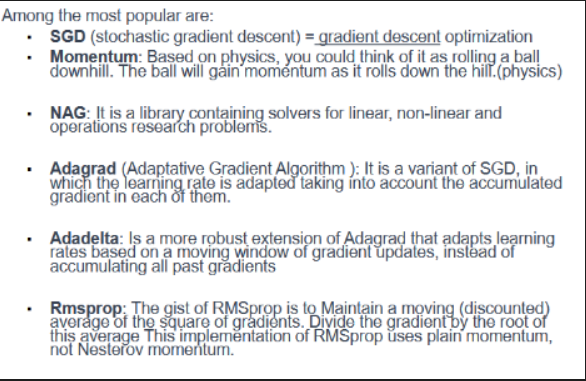

Methods to improve fitting:

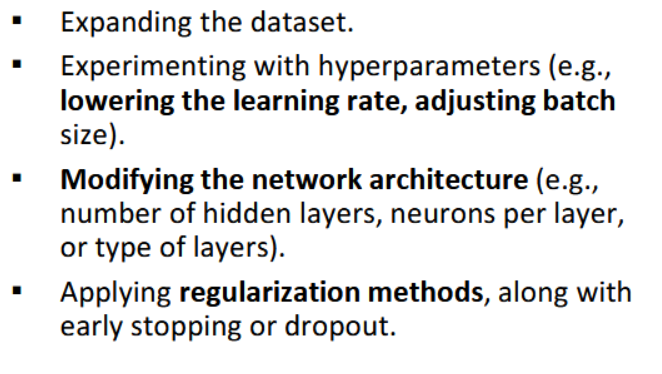
---

# 🧩 Normalization & Regularization

## 🧮 Normalization — Definition
Normalization is a technique used to **stabilize and speed up training** by adjusting activations (or inputs) so they have a **consistent mean and variance**.  
This helps gradients flow more smoothly and prevents exploding or vanishing gradients.

---

## 🔧 Regularization — Definition
Regularization is used to **reduce overfitting** by constraining the model’s capacity to memorize data.  
It improves **generalization** on unseen data.

🧱 Common regularization methods:
- **Dropout** – randomly deactivate neurons during training  
- **Weight decay (L2 penalty)** – discourages large weights  
- **Early stopping** – stop training before overfitting begins  
- **Data augmentation** – increases data variety synthetically  

---

## 🧠 Types of Normalization in Deep Learning

| **Normalization Type** | **Normalizes Over** | **Typical Use Case** | **Description** |
|--------------------------|----------------------|-----------------------|------------------|
| **BatchNorm** | Batch + spatial dimensions | **CNNs (vision)** | Normalizes each channel across the batch; stabilizes training and allows higher learning rates. |
| **LayerNorm** | All features per sample | **Transformers, NLP** | Normalizes across features of a single example; independent of batch size. |
| **InstanceNorm** | Spatial dimensions per channel | **Style transfer, GANs** | Normalizes each channel for each image separately; removes instance-specific contrast. |
| **GroupNorm** | Groups of channels | **Small batches (CNNs)** | Divides channels into groups and normalizes within each; good alternative when BatchNorm fails with small batch sizes. |

---

## 🧭 Quick Intuition
- **BatchNorm → Vision (big batches)**  
- **LayerNorm → NLP / Transformers**  
- **InstanceNorm → Image style / GANs**  
- **GroupNorm → Small-batch CNNs**

---

✅ **Summary Tip**
> 🧩 Normalization = stable training  
> 🧱 Regularization = better generalization

- - - 
## 🔹 Network Types

| Type | Purpose |
|------|----------|
| **Perceptron** | Single neuron, binary decisions |
| **Feed Forward (FFN)** | Fully connected layers |
| **Deep Feed Forward (DFFN)** | Multiple FF layers |
| **CNN** | Image data |
| **RNN** | Sequential data |
| **LSTM / GRU** | Handle long-term dependencies |

---

## 🔹 CNNs (Convolutional Neural Networks)

**Key Ideas**
- **Weight Sharing:** same filters reused → less params  
- **Hierarchy:** local → complex features  
  (edges → textures → objects)

**Kernel / Filter**
\[
y = w * x + b
\]

**Linear vs Convolutional**
- Linear ignores spatial relation  
- Convolution exploits pixel locality (both axes)
CNNs have advantages over linear networks for image processing because they ==preserve spatial relationships, automatically learn hierarchical features without manual engineering, and are more computationally efficient due to weight sharing and local connectivity==. These characteristics allow CNNs to handle high-dimensional image data effectively, achieve better accuracy, and be less prone to overfitting compared to linear networks

Spatial feature preservation
- CNNs treat pixels as spatially related, unlike linear networks that see them as independent features.
- This is crucial for image processing, as the arrangement of pixels (e.g., edges, corners, shapes) contains important information. 
Automatic hierarchical feature learning 
- CNNs automatically learn features, moving from simple ones like edges in early layers to more complex objects in deeper layers.
- This eliminates the need for manual feature engineering, saving time and improving performance. 
Computational efficiency and parameter reduction -->more efficient and faster to train
	**Weight sharing** (same weights are reused)
	**Local connectivity:** Neurons in a CNN are only connected to a small, local region of the input, rather than every neuron in the previous layer.

The hierarchy: edges/textures → object parts → objects
- **Lower layers** of a CNN detect simple features like edges and gradients.
- **Middle layers** combine these into more complex features and object parts.
- **Higher layers** synthesize these parts to identify the complete object [1, 4].

---

## 🔹 Pooling Layers

- Reduce dimensionality, add non-linearity  
- **Max Pooling:**  
  \[
  f_c(x) = \max_{i,j}(x_{i,j,c})
  \]
- Smaller feature maps, more abstract representation  
- Flatten → FC layers → classification

**Padding:** Keeps same spatial size  
**Stride:** Step of receptive field  
**Dilation:** Increases receptive field spacing  
**Groups:** Reduce computation by splitting channels

Average Pooling, Max Pooling, and Global Average Pooling are all forms of pooling layers used in Convolutional Neural Networks (CNNs) to ==down-sample feature maps==, reduce computational complexity, and introduce translation invariance. The core difference lies in the **operation performed** within the defined region and the **extent of that region**

**MaxPooling** 
- selects max from a local window 
- reduces espacial dims (H,W)
- ->predominant features (sharp edges/ bright pixels, provides a degree of translation invariance)
- Early and middle layers of CNNs for feature extraction.

**AveragePooling** 
- selects average from a local window 
- reduces espacial dims (H,W)
- -> more **generalized** and smoothed representation of the features
- less common in CNN's

**GlobalAveragePooling** 
- average of all values across feature map 
- reduces entire feature map to a 1x1 value per channel
- ->more **generalized** and smoothed representation of the features
- Used in the final layers, often as an alternative to fully connected layers, before the classification layer.

GAP is typically used towards the end of the network, just before the final classification layer (often a softmax layer). It replaces traditional, densely connected layers, which significantly reduces the number of parameters and helps prevent overfitting. It acts as a structural regularizer and makes the network more robust to spatial translations of the object in the input.

Pooling layers significantly affect the dimensionality of the data within a neural network by
==**reducing the spatial dimensions (height and width) of the feature maps**, while typically leaving the _depth_ (number of channels or filters) unchanged==

---

## 🔹 Receptive Field

- Area of input influencing one neuron (region of the input image that affects its activation.)
- Grows deeper in network  (receptive field grows) (e.g., edges → textures → objects).
- Controlled by kernel size, stride, dilation

Padding - Controuls output size -adding 0s so edges included, prevents shrinking of the spatial dimensions

Stride - controls downsizing - Moves the kernel by more than 1 pixel at a time → reduces output resolution. Larger stride = smaller output.

Dilation -controls space between kernel elements - Expands the receptive field without increasing kernel size or parameters (used in dilated convolutions).

Groups in Convolutions
	**Groups** split the input and output channels into independent sets.
	Each group performs its own convolution → fewer connections and parameters.  
	reduces computation and memory cost.  but less cross channel interaction


---

Typical PyTorch Training Pipeline
1. **Prepare Data**
   - Load datasets 
   - Apply **transforms** (resize, normalize, augment).
2. **Build Model**
   - Define a subclass of `nn.Module`.
   - Implement `__init__()` (layers) and `forward()` (data flow).
3. **Define Loss & Optimizer**
   - Example: `criterion = nn.CrossEntropyLoss()`
   - Example: `optimizer = torch.optim.Adam(model.parameters())`
4. **Training Loop**
   for epoch in range(epochs):
       optimizer.zero_grad()
       outputs = model(inputs)
       loss = criterion(outputs, labels)
       loss.backward()
       optimizer.step()

## 🔹 Data Augmentation

- Artificially increase data variability  
- Applied **during training**  
- Typical probability: 10–20%  
- Examples: rotation, flip, brightness, crop  
- -> reduce overfitting ('increase' training data)

---

## 🔹 Optimization & Regularization

### **SGD**
- Core optimizer  
- **Momentum (≈0.9):** smooths updates  
- May get stuck on flat regions

### **Adagrad**
- Per-weight adaptive LR  
- Frequent updates → smaller steps

### **RMSProp**
- Fixes Adagrad decay issue  
- Keeps LR adaptive

### **Adam**
- Combines Momentum + RMSProp  
- Fast convergence

---

## 🔹 Normalization

**Goal:** Stabilize training, fix vanishing/exploding gradients.

| Type | Normalizes over | Best for |
|------|------------------|----------|
| **BatchNorm** | Batch + spatial dims | CNNs, large batches |
| **LayerNorm** | Features per sample | NLP, Transformers |
| **InstanceNorm** | Spatial per channel | Style transfer, GANs |
| **GroupNorm** | Groups of channels | Small batches |

---

## 🔹 Regularization

**Purpose:** Reduce overfitting

**Techniques:**
- **Dropout:** randomly disable neurons → learn redundancy  
- **Early Stopping:** stop when validation loss stops improving  
- **Weight Decay:** shrink weights each step  
- **L1/L2 Regularization:** penalize large weights  
  - L1 → absolute value  
  - L2 → squared value  
  - Added to loss function (not same as weight decay)

---

## 🔹 Residual & Skip Connections

- Add input directly to output of later layers  
- Prevent **vanishing gradients**  
- Enable **very deep** networks (e.g. 1000+ layers)  
- Skip connections = smoother representation transitions

---

## 🔹 Learning Rate Scheduling

- **Step LR:** reduce LR after fixed epochs  
- **Multi-Step LR:** reduce LR at multiple defined epochs  
- Helps converge to minima

---

## 🔹 Overfitting vs Underfitting

| Problem | Symptoms | Fix |
|----------|-----------|-----|
| **Overfitting** | High train acc, low val acc | More data, stronger augmentation, dropout↑, regularization↑, smaller model |
| **Underfitting** | Low train + val acc | Bigger model, more epochs, LR↑, regularization↓ |

---

## 🔹 Ensemble Learning

- Combine multiple models → better accuracy (+1–3%)  
- Each model overfits differently → combined model generalizes better  
- Usually uses **different seeds, data splits, augmentations**

---

## 🔹 Transfer Learning

- Reuse pretrained networks (e.g. ResNet, VGG)  
- Train only **final layers** for new dataset  
- Works with **small datasets (≈1000 images)**  
- Freeze earlier layers → fine-tune final ones

---

## 🔹 RNNs & Sequence Models

- Keep **temporal order** of inputs  
- Reuse same weights across timesteps  
- Each neuron connects to its **previous state**

### Variants
| Model | Purpose |
|--------|----------|
| **RNN** | Sequential dependency modeling |
| **LSTM** | Handles long-term memory |
| **GRU** | Simplified LSTM (fewer gates) |

**Unfolding:** visualize temporal connections of one neuron through time.

---

## 🧩 Core Concepts Recap

- **Epoch / Step:** iteration structure  
- **Loss:** guides training  
- **Activation:** non-linearity  
- **Optimizer:** updates weights  
- **Regularization:** prevents overfitting  
- **Normalization:** stabilizes gradients  
- **Residuals:** improve deep training  
- **Pooling:** dimension reduction  
- **Receptive Field:** input region seen by neuron  
- **Augmentation:** expands dataset  
- **Transfer Learning:** reuse pretrained knowledge  
- **RNNs:** for sequential/temporal data

---

🧭 **Focus for exam:**
- Explain *why* normalization helps  
- Compare *BatchNorm vs LayerNorm*  
- Describe *CNN vs Linear*  
- Understand *Dropout, EarlyStopping, LR Scheduling*  
- Know *SGD, Adam, RMSProp differences*  
- Compute *iterations/epoch relationships*  
- Understand *receptive field growth* and *pooling purpose*  
- Recognize *overfitting vs underfitting patterns*


# 🔥 Deep Learning – Full Summary (Second Half + Tema 1 Review)

---

# 🧩 Tema 1 — Python, Packages, PyTorch Basics

## Type Hints
- Type hints **do not run** during program execution.  
- They are checked by external tools such as **mypy**.
- Improve readability and help catch bugs.

## Black (formatter)
- A tool that **automatically formats Python code**.
- Ensures consistent style across the project.

## Packages and `__init__.py`
- A folder is recognized as a **Python package** when it contains an `__init__.py` file.
- This file can be empty or can initialize package-level variables.

## Class Methods and Decorators
- A `@classmethod` takes **cls** as first argument (reference to the class).
- Decorators wrap functions to modify behavior.

## Indexing in Python
- `[i]`: element access  
- `[i:j]`: slicing  
- `[..., :]`: ellipsis for skipping dimensions  
- `x[..., 0]`: get last dimension index

## NumPy Array vs PyTorch Tensor
| NumPy Array | Torch Tensor |
|-------------|--------------|
| CPU only | CPU or GPU |
| No gradient tracking | Records computation graph for autograd |
| Great for math ops | Designed for DL + GPU parallelism |

## Array vs List
- **List**: dynamic, flexible, heterogeneous
- **Array / Tensor**: fixed type, optimized for numeric computation

## Wheels (`.whl`)
- Precompiled Python packages.  
- Faster install (no compilation needed).  
- PyTorch wheels depend on:  
  - PyTorch version  
  - CUDA version  
  - OS  
  - CPU/GPU build

## Broadcasting
Allows operations between tensors of **different shapes** by expanding them implicitly.

## `detach()` vs `clone()`
- `clone()` copies data **but keeps** the computational graph.
- `detach()` removes the tensor from the graph  
  (needed before backprop if you don’t want gradients to flow into it).

## Saving Models
- `state_dict`: only stores **parameters** → must re-instantiate the model class.
- `torch.save(model)` + `torch.load()` → saves entire model but depends on file structure (uses pickle).
- `torch.jit.trace()` / `torch.jit.script()` → export models **without code dependencies**.

## `torch.inference_mode()`
- More efficient than `no_grad()`
- Disables autograd **and** frees more internal metadata.

## CPU vs GPU
- **CPU**: few but powerful cores → good for sequential logic  
- **GPU**: thousands of small cores → perfect for matrix ops in parallel

## DataLoader Options
- `drop_last=True`: removes last incomplete batch  
- `shuffle=True`: prevents model from memorizing order  
  (stabilizes training, reduces bias)

---

# 🌀 Recurrent Neural Networks (RNNs)

RNNs handle **sequences** where order matters.

## Why RNN?
Fully-connected networks ignore order.  
RNNs maintain a **hidden state** that carries temporal information.

## Unfolding Through Time
A single recurrent unit is unrolled into **T copies**, one per timestep.

---

# 🧠 LSTM — Long Short-Term Memory

LSTMs solve the **vanishing gradient problem** via gates:

- Forget gate  
- Input gate  
- Output gate  

Internal states:
- `h_{t}` → hidden state (short-term memory)
- `c_{t}` → cell state (long-term memory)

---

# ⚙️ GRU — Gated Recurrent Unit

Like LSTM but simpler:
- Reset gate `r_t`
- Update gate `z_t`
- Only **one memory state**

Faster to train, robust for many tasks.

---

# 🧱 RNN Architectures

### Many-to-Many
- Useful for translation, speech recognition  
- *Delayed* many-to-many for languages with important endings (e.g., Japanese)

### Many-to-One
- Sentiment analysis  
- Classification  
- Anomaly detection

### Stacked Architectures
| Model | Strength |
|-------|----------|
| Stacked RNN | short memory, simple series |
| Stacked LSTM | long dependencies, language/audio |
| Stacked GRU | simpler than LSTM, still strong |

---

# 🌪️ Sentiment Analysis and NLP with RNNs

### Bag of Words (BoW)
Counts word frequencies — loses order.

### TF-IDF
Weights rare but important words more.

### Latent Semantic Analysis (LSA)
Dimensionality reduction on document-word matrices.

### RNN Approach
- Still needs preprocessing (tokenization, padding)  
- Learns embeddings instead of using raw frequencies  
- Good for long dependencies (LSTM/GRU preferred)

### Padding
Zeros added so sequences in batch have same length.

### Encoders
- `stoi`: string → index  
- `itos`: index → string  

### Levenshtein vs Embeddings
- Edit distance: syntactic similarity  
- Embeddings: semantic similarity (meaning)

---

# 🔄 RNN Implementation Details

### Hidden State Update
$H_t = X_t W_xh + H_{t-1} W_hh + b_h$


### Bidirectional RNNs
- Process sequence left→right and right→left  
- Reduce bias toward end of sentence  
- Final representation = concat of forward + backward hidden states

### Gradient Clipping
Prevents exploding gradients in long sequences.

### Sequence-to-Sequence (Encoder–Decoder)
Used for translation, Q&A, summarization.

Tokens:
- `<bos>`: begin sequence  
- `<eos>`: end sequence  

---

# 🔍 Attention and Transformers

### Idea of Attention
Weight hidden states depending on their relevance.

Each token asks:  
**"Where should I pay attention while producing the next word?"**

### Multi-Head Attention
- Many attention mechanisms in parallel  
- Each head focuses on different patterns  
- Improves expressiveness

### Positional Encoding
Adds position information since transformers are permutation-invariant.

### Vision Transformers (ViT)
- Image split into **patches**, treated as tokens  
- Typically only an encoder is used

---

# 🤖 Autoencoders (Unsupervised Learning)

### Autoencoder Structure
- **Encoder** compresses data  
- **Decoder** reconstructs input  
- Latent space is smaller → forces model to learn important features

### Sparse Autoencoders
- Latent dimension is larger  
- Extra penalty pushes most activations to zero  
- Used for feature discovery

### Denoising Autoencoder
- Add noise to input  
- Model learns to reconstruct clean data  
- Helps robustness

### Contractive Autoencoders
- Penalize sensitivity of latent space (derivatives)  
- Learn stable representations  
- Related to manifold learning (PCA/UMAP competitors)

---

# 🎨 Variational Autoencoders (VAE)

### Latent Space as Distributions
Each data point mapped to:
- mean vector μ  
- variance vector σ²  

We sample from N(μ, σ²) to generate new images.

### KL Divergence
Added to loss to align latent distributions.

### Reparameterization Trick
Instead of sampling  
`z ~ N(μ, σ²)`  
we compute  
`z = μ + σ * ε` where `ε ~ N(0, 1)`  
This separates randomness → allows gradients to flow.

VAEs: stable but blurrier images compared to GANs.

---

# 🥊 GANs — Generative Adversarial Networks

### Two networks:
- **Generator**: turns noise into images  
- **Discriminator**: distinguishes real vs fake

Trained adversarially.  
If one becomes too strong → collapse.

### Loss Function (Binary Cross-Entropy)
Discriminator tries to classify real/fake.  
Generator tries to fool discriminator.

### Advantages
- High-quality images  
- Good diversity  

### Disadvantages
- Difficult to train  
- Unstable, collapse modes

GANs used for:
- Image generation  
- Super-resolution  
- Image-to-image translation  
- Text-to-image (before diffusion era)

Now replaced mostly by **Diffusion Models**.

---

# 🪄 Object Detection & Segmentation (Short)

- Detection: bounding boxes + labels  
- Segmentation: pixel-level classification  
- Models: Faster R-CNN, YOLO, U-Net

---

# 🧠 Fundamentals Recap

- Inputs defined by first layer  
- Hidden layers optional  
- Early stopping “patience”: number of epochs without improvement  
- Activation → gives nonlinearity  
- Padding often 1 for simple convs  
- Kernel = filter (region over which convolution operates)  
- Pooling reduces spatial size  
- Convolutions expand channels  
- RNN: short memory  
- LSTM/GRU: long memory  
- Bidirectional RNNs: process forward and backward sequences  
- Encoder–decoder for translation / QA

---

# 🎯 End of Summary
